# Modelo de aprobación de tarjetas de crédito
**Regresión Logística dentro de un Pipeline de scikit-learn**

Objetivo: predecir si la solicitud de un cliente será **rechazada** (`label = 1`) o aprobada (`label = 0`).
La clase positiva es siempre **rechazada (1)** y `random_state=42` en todo lo aleatorio.

**Índice**
1. Carga y unión de los datos (y duplicados)
2. Análisis de nulos
3. Limpieza de variables (y tipos de datos)
4. Variables categóricas: codificación elegida
5. División en entrenamiento y test
6. Pipeline
7. Desbalance de clases
8. Métricas de rendimiento
9. Matriz de confusión (y coeficientes del modelo)
10. Conclusiones
+ Declaración de uso de IA

In [1]:
import warnings
from sklearn.exceptions import UndefinedMetricWarning
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import set_config
from sklearn.base import clone
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, TargetEncoder, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve

# Solo se silencia el aviso esperado del Dummy (precision indefinida al no predecir ninguna positiva)
warnings.filterwarnings("ignore", category=UndefinedMetricWarning)
set_config(display="diagram")
RS = 42

## 1. Carga y unión de los datos
La clave de unión es `Ind_ID`. Antes de unir compruebo que es única en los dos ficheros y que contienen los mismos clientes.

In [2]:
# Características de cada cliente y, por separado, la decisión (label)
X_raw = pd.read_csv("data/Credit_card.csv")
y_raw = pd.read_csv("data/Credit_card_label.csv")

print("Filas:", X_raw.shape[0], "y", y_raw.shape[0])
print("Ind_ID único en características:", X_raw["Ind_ID"].is_unique)
print("Ind_ID único en etiquetas:", y_raw["Ind_ID"].is_unique)
print("Mismos IDs en ambos ficheros:", set(X_raw["Ind_ID"]) == set(y_raw["Ind_ID"]))

Filas: 1548 y 1548
Ind_ID único en características: True
Ind_ID único en etiquetas: True
Mismos IDs en ambos ficheros: True


In [3]:
# validate="one_to_one" daría error si alguna clave estuviera repetida
df = X_raw.merge(y_raw, on="Ind_ID", how="inner", validate="one_to_one")
print("Filas tras la unión:", len(df))
df.head()

Filas tras la unión: 1548


,Ind_ID,GENDER,Car_Owner,Propert_Owner,CHILDREN,Annual_income,Type_Income,EDUCATION,Marital_status,Housing_type,Birthday_count,Employed_days,Mobile_phone,Work_Phone,Phone,EMAIL_ID,Type_Occupation,Family_Members,label
0,5008827,M,Y,Y,0,180000.0,Pensioner,Higher education,Married,House / apartment,-18772.0,365243,1,0,0,0,NaN,2,1
1,5009744,F,Y,N,0,315000.0,Commercial associate,Higher education,Married,House / apartment,-13557.0,-586,1,1,1,0,NaN,2,1
2,5009746,F,Y,N,0,315000.0,Commercial associate,Higher education,Married,House / apartment,NaN,-586,1,1,1,0,NaN,2,1
3,5009749,F,Y,N,0,NaN,Commercial associate,Higher education,Married,House / apartment,-13557.0,-586,1,1,1,0,NaN,2,1
4,5009752,F,Y,N,0,315000.0,Commercial associate,Higher education,Married,House / apartment,-13557.0,-586,1,1,1,0,NaN,2,1


**Tipo de unión:** *inner join* **uno a uno** por `Ind_ID`. Como los dos ficheros tienen los mismos 1.548 clientes, no se pierde ni se inventa ninguna fila; `validate="one_to_one"` protege además frente a claves repetidas.

### Duplicados
Duplicado exacto (con `Ind_ID`) no hay ninguno, pero puede haber **clientes distintos con exactamente las mismas características**.

In [4]:
# Duplicado = mismas características (sin contar el ID); se mira con y sin la etiqueta
columnas = [c for c in df.columns if c not in ("Ind_ID", "label")]
print("Duplicados exactos (con Ind_ID):", df.duplicated().sum())
print("Duplicados en características (sin ID):", df.duplicated(subset=columnas).sum())
print("Duplicados en características y misma etiqueta:", df.duplicated(subset=columnas + ["label"]).sum())
print(f"Tasa de rechazo antes de eliminar: {df['label'].mean():.3f}")

Duplicados exactos (con Ind_ID): 0
Duplicados en características (sin ID): 171
Duplicados en características y misma etiqueta: 162
Tasa de rechazo antes de eliminar: 0.113


**Decisión: eliminar los duplicados que tienen también la misma etiqueta (162 filas).** Para el modelo son filas indistinguibles. Si se quedaran, una copia podría caer en *train* y otra en *test*, y el modelo "reconocería" al cliente: las métricas saldrían infladas (fuga de datos).

**Los contradictorios se conservan.** Tras la limpieza quedan 9 perfiles que aparecen con las dos decisiones (18 filas implicadas). Son ruido real de la decisión histórica y no hay criterio para elegir cuál es la "buena", así que se mantienen y se citan como limitación.

**Efecto sobre el target:** al eliminar, la tasa de rechazo baja de ~11,3 % a ~9,9 %, porque entre los duplicados había más rechazadas que la media. Es esperable (perfiles que se repiten), pero conviene saberlo: el desbalance real del problema es algo mayor en el dataset original.

In [5]:
df = df.drop_duplicates(subset=columnas + ["label"]).reset_index(drop=True)
print("Filas tras eliminar duplicados:", len(df))
print("Perfiles con etiquetas contradictorias (filas implicadas):", df.duplicated(subset=columnas, keep=False).sum())
print(df["label"].value_counts(normalize=True).round(3))

Filas tras eliminar duplicados: 1386
Perfiles con etiquetas contradictorias (filas implicadas): 18
label
0    0.901
1    0.099
Name: proportion, dtype: float64


## 2. Análisis de nulos

In [6]:
from scipy.stats import fisher_exact

# Cuántos nulos hay por columna y en qué porcentaje
nulos = df.isna().sum()
nulos = nulos[nulos > 0].to_frame("n_nulos")
nulos["% nulos"] = (nulos["n_nulos"] / len(df) * 100).round(2)
display(nulos)

# ¿Se relacionan los nulos con el target? Tasa de rechazo con/sin nulo y test exacto de Fisher
for col in nulos.index:
    m = df[col].isna()
    tabla = [[(df.loc[m, "label"] == 1).sum(), (df.loc[m, "label"] == 0).sum()],
             [(df.loc[~m, "label"] == 1).sum(), (df.loc[~m, "label"] == 0).sum()]]
    p = fisher_exact(tabla)[1]
    print(f"{col:16s} rechazo con nulo: {df.loc[m, 'label'].mean():.2f} | sin nulo: {df.loc[~m, 'label'].mean():.2f} | p-valor Fisher: {p:.4f}")

# ¿Y con otras variables? (Type_Occupation vs Type_Income)
display(pd.crosstab(df["Type_Income"], df["Type_Occupation"].isna(), normalize="index").round(2))

,n_nulos,% nulos
GENDER,7,0.51
Annual_income,23,1.66
Birthday_count,22,1.59
Type_Occupation,438,31.60


GENDER           rechazo con nulo: 0.71 | sin nulo: 0.10 | p-valor Fisher: 0.0002
Annual_income    rechazo con nulo: 0.35 | sin nulo: 0.09 | p-valor Fisher: 0.0010
Birthday_count   rechazo con nulo: 0.09 | sin nulo: 0.10 | p-valor Fisher: 1.0000
Type_Occupation  rechazo con nulo: 0.11 | sin nulo: 0.10 | p-valor Fisher: 0.6286


Type_Occupation,False,True
Type_Income,,
Commercial associate,0.80,0.20
Pensioner,0.02,0.98
State servant,0.83,0.17
Working,0.84,0.16


| Columna | Nulos | Estrategia | Justificación |
|---|---|---|---|
| `Type_Occupation` | ~32 % | **Categoría nueva "Desconocido"** | Demasiados para eliminar. No son aleatorios: casi todos los pensionistas (98 %) no tienen ocupación. La ausencia ya es información. Sin relación con el target (11 % frente a 10 %). |
| `Annual_income` | ~1,7 % | **Mediana + indicador de nulo** | Variable asimétrica con valores extremos: la mediana es robusta, la media se desplazaría. Los nulos **sí** se relacionan con el target (35 % de rechazo frente a 9 %, Fisher p ≈ 0,001), así que además de imputar añado una columna 0/1 "ingreso ausente" para no perder esa señal. |
| `Birthday_count` | ~1,6 % | **Mediana** | Pocos nulos y sin relación con el target (9 % frente a 10 %). |
| `GENDER` | ~0,5 % | **Moda + indicador de nulo** | Solo 7 filas, pero 5 son rechazadas (71 % frente a 10 %, Fisher p ≈ 0,0002). Con tan pocos casos hay que ser prudente (podría ser casualidad o un defecto de captura de datos), pero como el contraste es significativo, la moda por sí sola tiraría esa información. Imputo con la moda (es una binaria; una categoría nueva rompería el *One-Hot* binario) y marco los nulos con un indicador. |

La imputación y los indicadores se hacen **dentro del Pipeline** (apartado 6), ajustados solo con *train*.

## 3. Limpieza de variables

In [7]:
print("Valores distintos de Mobile_phone:", df["Mobile_phone"].unique())
print("Employed_days > 0:", (df["Employed_days"] > 0).sum(), "filas, valor:", df.loc[df["Employed_days"] > 0, "Employed_days"].unique(),
      "| Type_Income:", df.loc[df["Employed_days"] > 0, "Type_Income"].unique())
df[["Birthday_count", "Employed_days"]].describe().round(0)

Valores distintos de Mobile_phone: [1]
Employed_days > 0: 237 filas, valor: [365243] | Type_Income: <StringArray>
['Pensioner']
Length: 1, dtype: str


,Birthday_count,Employed_days
count,1364.0,1386.0
mean,-16034.0,60265.0
std,4217.0,138577.0
min,-24946.0,-14887.0
25%,-19543.0,-3154.0
50%,-15612.0,-1542.0
75%,-12445.0,-412.0
max,-7705.0,365243.0


**Columnas eliminadas**
- `Ind_ID`: es solo un identificador, no aporta información (el modelo memorizaría clientes).
- `Mobile_phone`: vale 1 para todos (varianza cero), no distingue a nadie.

**Columnas transformadas** (son operaciones fila a fila que no aprenden nada de los datos, así que no hay fuga y se pueden hacer antes de dividir):
- `Birthday_count` son **días desde el nacimiento en negativo**. Lo paso a `Age` en **años**.
- `Employed_days` también está en días negativos, pero **365243 es un código** que solo tienen los pensionistas (sin empleo). Lo separo en `Years_employed` (años de antigüedad, 0 si no trabaja) y `Not_employed` (0/1).

In [8]:
# Se eliminan el identificador y la columna constante
df = df.drop(columns=["Ind_ID", "Mobile_phone"])

# Edad en años (los días vienen en negativo)
df["Age"] = -df["Birthday_count"] / 365.25
# 365243 es un código de "no trabaja": lo separamos en un indicador 0/1 y en años reales de antigüedad
df["Not_employed"] = (df["Employed_days"] == 365243).astype(int)
df["Years_employed"] = np.where(df["Not_employed"] == 1, 0, -df["Employed_days"] / 365.25)
df = df.drop(columns=["Birthday_count", "Employed_days"])

df[["Age", "Years_employed", "Not_employed"]].describe().round(1)

,Age,Years_employed,Not_employed
count,1364.0,1386.0,1386.0
mean,43.9,6.0,0.2
std,11.5,6.5,0.4
min,21.1,0.0,0.0
25%,34.1,1.1,0.0
50%,42.7,4.2,0.0
75%,53.5,8.6,0.0
max,68.3,40.8,1.0


**¿Qué variables aportan información? Asociación de cada una con el target**

Para decidir qué columnas sobran no basta con intuirlo: mido la relación de cada variable con el rechazo. Para las categóricas y binarias uso el test **chi-cuadrado** (con la **V de Cramér** como tamaño del efecto, 0 = nada, 1 = total) y para las numéricas el test **Mann-Whitney** (compara su distribución entre rechazadas y aprobadas). Es un análisis exploratorio descriptivo (no ajusta nada), igual que el de nulos del apartado 2.

Además reviso dos solapes que ya sospechaba: `CHILDREN` con `Family_Members` y `Not_employed` con `Type_Income`.

In [9]:
from scipy.stats import chi2_contingency, mannwhitneyu

filas = []
for col in df.columns.drop("label"):
    if pd.api.types.is_numeric_dtype(df[col]) and df[col].nunique() > 10:
        # numérica continua: Mann-Whitney entre rechazadas y aprobadas
        p = mannwhitneyu(df.loc[df["label"] == 1, col].dropna(), df.loc[df["label"] == 0, col].dropna()).pvalue
        filas.append((col, "numérica", p, np.nan))
    else:
        # categórica, binaria o conteo pequeño: chi-cuadrado (los nulos cuentan como un nivel más)
        tabla = pd.crosstab(df[col].fillna("nulo").astype(str), df["label"])
        chi2, p, _, _ = chi2_contingency(tabla)
        filas.append((col, f"{tabla.shape[0]} niveles", p, np.sqrt(chi2 / (tabla.values.sum() * (min(tabla.shape) - 1)))))
asociacion = pd.DataFrame(filas, columns=["variable", "tipo", "p-valor", "V de Cramér"]).set_index("variable").sort_values("p-valor").round(4)
display(asociacion)

print("\nCorrelación CHILDREN - Family_Members:", round(df["CHILDREN"].corr(df["Family_Members"]), 2))
display(pd.crosstab(df["Type_Income"], df["Not_employed"]))

,tipo,p-valor,V de Cramér
variable,,,
GENDER,3 niveles,0.0000,0.1544
Years_employed,numérica,0.0006,NaN
Housing_type,6 niveles,0.0023,0.1157
Type_Income,4 niveles,0.0034,0.0993
CHILDREN,6 niveles,0.0414,0.0913
EDUCATION,5 niveles,0.0420,0.0846
Age,numérica,0.0606,NaN
Family_Members,7 niveles,0.0686,0.0919
Marital_status,5 niveles,0.0869,0.0766



Correlación CHILDREN - Family_Members: 0.89


Not_employed,0,1
Type_Income,,
Commercial associate,330,0
Pensioner,8,237
State servant,101,0
Working,710,0


**Decisión: mantener `Work_Phone`, `Phone` y `EMAIL_ID`, dejando constancia de que son las candidatas más débiles.** El test las señala como **variables sin asociación con el rechazo** (p-valores 0,43-0,73 y V de Cramér ≈ 0,01-0,02: tasas de rechazo casi idénticas con valor 0 y 1, entre 9 % y 12 %). Aun así las conservo por estos motivos:
- Son binarias 0/1 y no son constantes (a diferencia de `Mobile_phone`, que sí se elimina por tener varianza cero), así que no hay un motivo técnico para descartarlas por construcción.
- El test es univariante y "no significativo" significa que con estos datos no se detecta efecto, no que sea cero; con solo ~110 rechazadas en *train* el test tiene poca potencia.
- La regresión logística admite sin problema columnas poco informativas: si no aportan, su coeficiente tiende a 0 y apenas afectan a las predicciones. En el apartado 9 se ve que sus coeficientes son moderados (entre −0,15 y +0,30), muy por debajo de los de las variables más influyentes.
- Para quitarlas con rigor habría que demostrar con validación cruzada que no empeora el modelo; al ser una mejora opcional, queda señalada como posible mejora en las conclusiones (selección de variables dentro del Pipeline).

**Otras variables que se mantienen aunque su p-valor sea alto**
- `Annual_income`: es la variable básica de un estudio de crédito y su indicador de nulo sí se asocia al rechazo.
- `Car_Owner` y `Propert_Owner`: tampoco muestran asociación (p ≈ 0,6), pero tener coche o vivienda es una señal clásica de solvencia.
- `Not_employed`: es la codificación necesaria del código 365243 de `Employed_days`. Solapa con `Pensioner` de `Type_Income` (los 237 sin empleo son pensionistas), pero separa "no trabaja" de "0 años de antigüedad".
- `Type_Occupation`: tiene 19 niveles y con tan pocos casos el test pierde potencia.
- `CHILDREN` y `Family_Members`: correlación alta (0,89). Es multicolinealidad: no sesga las predicciones, pero sus coeficientes individuales no son interpretables por separado. Conservo las dos porque `Family_Members` incluye además a la pareja.

**Tipos de datos y memoria.** Antes de dividir ajusto los tipos de cada columna al rango real de sus valores: enteros pequeños (`int8`) para las binarias y los conteos, `float32` para las numéricas continuas y `category` para el texto con pocas categorías. Es una operación fila a fila que no aprende nada de los datos, así que no hay fuga. El dataset es pequeño y el ahorro no se nota en tiempo, pero es la decisión que escala si llegaran millones de solicitudes: menos memoria y operaciones más rápidas.

In [10]:
mem_antes = df.memory_usage(deep=True).sum()

enteros = ["label", "CHILDREN", "Family_Members", "Work_Phone", "Phone", "EMAIL_ID", "Not_employed"]
continuas = ["Annual_income", "Age", "Years_employed"]
categoricas = df.select_dtypes(exclude="number").columns
df[enteros] = df[enteros].astype("int8")
df[continuas] = df[continuas].astype("float32")
df[categoricas] = df[categoricas].astype("category")

mem_despues = df.memory_usage(deep=True).sum()
print(f"Memoria antes: {mem_antes / 1024:.0f} KB | después: {mem_despues / 1024:.0f} KB | ahorro: {1 - mem_despues / mem_antes:.0%}")
df.dtypes.to_frame("tipo").T

Memoria antes: 729 KB | después: 39 KB | ahorro: 95%


,GENDER,Car_Owner,Propert_Owner,CHILDREN,Annual_income,Type_Income,EDUCATION,Marital_status,Housing_type,Work_Phone,Phone,EMAIL_ID,Type_Occupation,Family_Members,label,Age,Not_employed,Years_employed
tipo,category,category,category,int8,float32,category,category,category,category,int8,int8,int8,category,int8,int8,float32,int8,float32


## 4. Variables categóricas: codificación elegida

| Variable | Codificación | Razón |
|---|---|---|
| `Type_Income` | **Target Encoding** (`TargetEncoder`) | Lo pide el enunciado: cada categoría se sustituye por su tasa de rechazo (suavizada). |
| `Type_Occupation` (18 categorías) | **Target Encoding** | Alta cardinalidad: One-Hot crearía ~19 columnas casi vacías. |
| `GENDER`, `Car_Owner`, `Propert_Owner` | **One-Hot** (`drop="if_binary"`) | Binarias: una columna 0/1. |
| `EDUCATION` | **Ordinal** | Tiene un orden natural (de menos a más estudios). |
| `Marital_status`, `Housing_type` | **One-Hot** | Nominales con pocas categorías, sin orden. |

**Escalado:** como en el PDF, `StandardScaler` es el estándar para la regresión logística (que depende de la escala de las variables). `Annual_income` es muy asimétrica y con valores extremos, así que antes de escalar le aplico `log1p`, como en los apuntes.

## 5. División en entrenamiento y test
Solo ~10 % de las solicitudes son rechazadas. Uso `stratify=y` para que **train y test mantengan la misma proporción de clases** (si no, el test podría quedarse con muy pocos casos de la clase minoritaria).

In [11]:
# stratify=y mantiene la proporción de rechazadas en train y test (hay desbalance)
X = df.drop(columns="label")
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RS)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print(f"Proporción de rechazadas -> total: {y.mean():.3f} | train: {y_train.mean():.3f} | test: {y_test.mean():.3f}")

Train: (1108, 17) | Test: (278, 17)
Proporción de rechazadas -> total: 0.099 | train: 0.099 | test: 0.097


## 6. Pipeline
Un mini-pipeline por tipo de columna (imputar → codificar/escalar), reunidos en un `ColumnTransformer`, y la regresión logística como último paso. Además se añaden dos **indicadores de nulo** (`Annual_income` y `GENDER`, ver apartado 2).

Este es el **Pipeline definitivo**: la regresión logística lleva `class_weight="balanced"`. La decisión se justifica en el apartado 7, donde se compara con la versión sin pesos y con el Dummy mediante validación cruzada **solo sobre train**. `fit` solo se hace con *train*.

In [12]:
# Orden natural de los estudios, de menos a más (para la codificación ordinal)
orden_educ = ["Lower secondary", "Secondary / secondary special", "Incomplete higher", "Higher education", "Academic degree"]
cv_te = KFold(n_splits=5, shuffle=True, random_state=RS)   # validación cruzada interna del TargetEncoder

# Columnas de cada grupo (se definen con nombre para que el ColumnTransformer sea legible)
col_ingresos = ["Annual_income"]
col_num = ["Age", "Years_employed", "CHILDREN", "Family_Members"]
col_nulos = ["Annual_income", "GENDER"]          # columnas con indicador de nulo
col_bin = ["GENDER", "Car_Owner", "Propert_Owner"]
col_nom = ["Marital_status", "Housing_type"]
col_ord = ["EDUCATION"]
col_type_income = ["Type_Income"]
col_ocupacion = ["Type_Occupation"]

# Un mini-pipeline para cada tipo de columna (imputar -> codificar/escalar)
# Ingresos: mediana (robusta a extremos), log1p para reducir la asimetría y escalado
pipe_ingresos = Pipeline([("imputar", SimpleImputer(strategy="median")),
                          ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                          ("escalar", StandardScaler())])
pipe_num = Pipeline([("imputar", SimpleImputer(strategy="median")),
                     ("escalar", StandardScaler())])
pipe_bin = Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                     ("onehot", OneHotEncoder(drop="if_binary", sparse_output=False))])
pipe_nom = Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                     ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
pipe_ord = Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                     ("ordinal", OrdinalEncoder(categories=[orden_educ])),
                     ("escalar", StandardScaler())])
# Target Encoding de Type_Income (pedido en el enunciado); el cv interno evita que la columna "vea" su propio target
pipe_te = Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                    ("target", TargetEncoder(cv=cv_te)),
                    ("escalar", StandardScaler())])
# Ocupación: los nulos pasan a ser una categoría propia "Desconocido" y luego Target Encoding
pipe_ocup = Pipeline([("imputar", SimpleImputer(strategy="constant", fill_value="Desconocido")),
                      ("target", TargetEncoder(cv=cv_te)),
                      ("escalar", StandardScaler())])

preprocesador = ColumnTransformer(
    transformers=[
        ("ingresos", pipe_ingresos, col_ingresos),
        ("num", pipe_num, col_num),
        ("nulos", MissingIndicator(features="all"), col_nulos),
        ("bin", pipe_bin, col_bin),
        ("nom", pipe_nom, col_nom),
        ("ord", pipe_ord, col_ord),
        ("type_income", pipe_te, col_type_income),
        ("ocupacion", pipe_ocup, col_ocupacion),
    ],
    remainder="passthrough",   # Work_Phone, Phone, EMAIL_ID y Not_employed ya son 0/1
)

# Pipeline DEFINITIVO: todo el preprocesado + LogisticRegression con class_weight="balanced" como último paso
pipe = Pipeline([("preprocesado", clone(preprocesador)),
                 ("modelo", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RS))])
pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocesado', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('ingresos', ...), ('num', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float,

In [13]:
# Así queda la matriz que recibe el modelo (el preprocesador solo se ajusta con train)
preprocesador.set_output(transform="pandas")
Xt = preprocesador.fit_transform(X_train, y_train)
print("Forma tras el preprocesamiento:", Xt.shape, "| nulos:", Xt.isna().sum().sum())
display(Xt.head(3).T.round(2))   # traspuesta y con 3 filas: se lee mejor que una tabla de 28 columnas

Forma tras el preprocesamiento: (1108, 28) | nulos: 0


,923,870,152
ingresos__Annual_income,1.303426,-0.736441,-1.276817
num__Age,-0.072047,0.364612,-0.290256
num__Years_employed,1.387704,-0.782277,-0.63972
num__CHILDREN,-0.526567,-0.526567,-0.526567
num__Family_Members,-0.178534,-0.178534,-1.192974
nulos__missingindicator_Annual_income,False,False,False
nulos__missingindicator_GENDER,False,False,False
bin__GENDER_M,0.0,0.0,0.0
bin__Car_Owner_Y,1.0,0.0,0.0
bin__Propert_Owner_Y,1.0,1.0,1.0


In [14]:
# fit con train: imputadores, encoders, escaladores y modelo aprenden SOLO de train (sin fuga de datos)
pipe.fit(X_train, y_train)
# en test solo se aplica lo aprendido
y_pred = pipe.predict(X_test)
print("Pipeline entrenado con", len(X_train), "filas de train y aplicado a", len(X_test), "filas de test.")

Pipeline entrenado con 1108 filas de train y aplicado a 278 filas de test.


## 7. Desbalance de clases
Comparo tres candidatos con el mismo preprocesado: un `DummyClassifier` que siempre predice la clase mayoritaria (aprobada), la regresión logística **sin** tener en cuenta el desbalance, y la regresión logística con `class_weight="balanced"` (los errores en la clase minoritaria pesan más).

**Primero, validación cruzada estratificada (5 folds) solo sobre *train*.** No es un requisito del enunciado: la uso para elegir entre los tres candidatos **sin mirar el test**, que queda reservado para la evaluación final. Después se muestran también los resultados en test.

In [15]:
# Los tres candidatos comparten el preprocesado del pipeline definitivo; solo cambia el estimador final
modelos = {
    "Dummy (siempre aprobada)": DummyClassifier(strategy="most_frequent"),
    "LogReg sin class_weight": LogisticRegression(max_iter=1000, random_state=RS),
    "LogReg class_weight=balanced": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RS),
}

# Validación cruzada estratificada SOLO con train: el preprocesado se reajusta en cada fold (sin fuga).
# n_jobs=-1 reparte los 5 folds entre los núcleos disponibles.
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)
metricas = ["accuracy", "precision", "recall", "f1", "roc_auc", "average_precision"]
filas_cv = []
for nombre, modelo in modelos.items():
    p = clone(pipe).set_params(modelo=modelo)
    cv = cross_validate(p, X_train, y_train, cv=skf, scoring=metricas, n_jobs=-1)
    filas_cv.append({"modelo": nombre,
                     **{m: f"{cv[f'test_{m}'].mean():.3f} ± {cv[f'test_{m}'].std():.3f}" for m in metricas}})
resultados_cv = pd.DataFrame(filas_cv).set_index("modelo").rename(columns={"average_precision": "PR-AUC", "roc_auc": "ROC-AUC"})
print("Validación cruzada (media ± desviación entre los 5 folds, solo train):")
resultados_cv

Validación cruzada (media ± desviación entre los 5 folds, solo train):


,accuracy,precision,recall,f1,ROC-AUC,PR-AUC
modelo,,,,,,
Dummy (siempre aprobada),0.901 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000,0.099 ± 0.000
LogReg sin class_weight,0.901 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.602 ± 0.061,0.214 ± 0.073
LogReg class_weight=balanced,0.640 ± 0.025,0.136 ± 0.017,0.491 ± 0.073,0.213 ± 0.026,0.602 ± 0.068,0.232 ± 0.089


In [16]:
# Resultados en test (los modelos se ajustan con todo train)
filas = []
for nombre, modelo in modelos.items():
    p = clone(pipe).set_params(modelo=modelo)
    p.fit(X_train, y_train)
    y_hat = p.predict(X_test)
    proba = p.predict_proba(X_test)[:, 1]          # probabilidad de rechazo, para las métricas independientes del umbral
    filas.append({"modelo": nombre,
                  "accuracy": accuracy_score(y_test, y_hat),
                  "precision": precision_score(y_test, y_hat, zero_division=0),
                  "recall": recall_score(y_test, y_hat),
                  "F1": f1_score(y_test, y_hat),
                  "ROC-AUC": roc_auc_score(y_test, proba),
                  "PR-AUC": average_precision_score(y_test, proba)})

resultados = pd.DataFrame(filas).set_index("modelo").round(3)
resultados

,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
modelo,,,,,,
Dummy (siempre aprobada),0.903,0.000,0.000,0.000,0.500,0.097
LogReg sin class_weight,0.903,0.000,0.000,0.000,0.686,0.264
LogReg class_weight=balanced,0.669,0.158,0.556,0.246,0.672,0.239


**En validación cruzada (solo train)** la regresión logística sin pesos se comporta igual que el Dummy en las métricas de clasificación: no predice ninguna solicitud rechazada (recall 0). Con `class_weight="balanced"` la accuracy baja (0,64 ± 0,03) pero el recall sube a 0,49 ± 0,07 y el F1 a 0,21 ± 0,03. Esa comparación, hecha sin tocar el test, es la que justifica que el **Pipeline definitivo** lleve `class_weight="balanced"`.

Dato clave: el **ROC-AUC es el mismo (0,60) con y sin pesos**. `class_weight` no hace que el modelo ordene mejor a los clientes; solo **desplaza el umbral efectivo** para que se anime a predecir la clase minoritaria. Por eso mejora el recall y empeora la accuracy, y por eso sigue siendo modesto: la capacidad de discriminación es la misma.

En test se confirma el mismo patrón (Dummy y modelo sin pesos: recall 0; modelo con pesos: recall 0,56). Ese recall de test cae dentro de la variación entre folds de la CV (0,49 ± 0,07), así que la diferencia entre CV y test es compatible con ruido, dado que el test solo tiene 27 positivos.

## 8. Métricas de rendimiento
Modelo final: **Regresión Logística con `class_weight="balanced"`**, clase positiva = rechazada (1).

In [17]:
# Modelo final: el Pipeline definitivo (regresión logística con class_weight="balanced")
y_pred = pipe.predict(X_test)   # el Pipeline definitivo del apartado 6

print("Accuracy :", round(accuracy_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred), 3))
print("Recall   :", round(recall_score(y_test, y_pred), 3))
print("F1-score :", round(f1_score(y_test, y_pred), 3))

# Métricas que no dependen del umbral 0,5: miden cuánto separa el modelo a rechazadas de aprobadas
proba = pipe.predict_proba(X_test)[:, 1]
print("ROC-AUC  :", round(roc_auc_score(y_test, proba), 3), "(0,5 = azar)")
print("PR-AUC   :", round(average_precision_score(y_test, proba), 3), f"(azar = prevalencia = {y_test.mean():.3f})")

Accuracy : 0.669
Precision: 0.158
Recall   : 0.556
F1-score : 0.246
ROC-AUC  : 0.672 (0,5 = azar)
PR-AUC   : 0.239 (azar = prevalencia = 0.097)


**¿Por qué la accuracy no es suficiente?** Con ~90 % de solicitudes aprobadas, el Dummy que **nunca rechaza a nadie** ya tiene ~90 % de accuracy y, sin embargo, no detecta ni una solicitud rechazada (recall = 0). La accuracy la domina la clase mayoritaria y oculta el comportamiento en la clase que interesa. Por eso miramos:
- **Precision**: de las que el modelo marca como rechazadas, cuántas lo son de verdad.
- **Recall**: de las que debían rechazarse, cuántas detecta.
- **F1**: media armónica de las dos.

**Métricas que no dependen del umbral (ROC-AUC y PR-AUC).** Precision, recall y F1 dependen del umbral 0,5, así que una sola cifra de test puede engañar. El ROC-AUC (0,5 = azar) y el PR-AUC (el azar equivale a la prevalencia, ~0,10) miden si el modelo **ordena** bien a las solicitudes rechazadas por encima de las aprobadas, con independencia del umbral. En el modelo final: ROC-AUC ≈ 0,67 y PR-AUC ≈ 0,24, es decir, mejor que el azar (el PR-AUC es ~2,4 veces la prevalencia), pero con una capacidad de discriminación modesta.

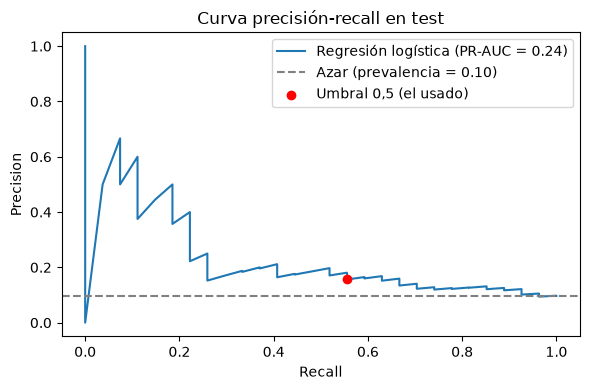

In [18]:
# Curva precisión-recall del modelo final: cada punto es un umbral de decisión distinto
precision, recall, umbrales = precision_recall_curve(y_test, proba)
plt.figure(figsize=(6, 4))
plt.plot(recall, precision, label=f"Regresión logística (PR-AUC = {average_precision_score(y_test, proba):.2f})")
plt.axhline(y_test.mean(), color="grey", ls="--", label=f"Azar (prevalencia = {y_test.mean():.2f})")
plt.scatter(recall_score(y_test, y_pred), precision_score(y_test, y_pred), color="red", zorder=3, label="Umbral 0,5 (el usado)")
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title("Curva precisión-recall en test")
plt.legend(); plt.tight_layout(); plt.show()

La curva muestra el compromiso entre precision y recall al mover el umbral. El punto rojo (umbral 0,5) es el que usamos: recall alto a cambio de precision baja. Sirve de evidencia para dos afirmaciones de las conclusiones: (1) la precision es baja en casi todo el rango de umbrales, no solo en este punto, por lo que el modelo discrimina poco; (2) el umbral se podría mover según el coste real de cada error, que es una mejora pendiente.

## 9. Matriz de confusión

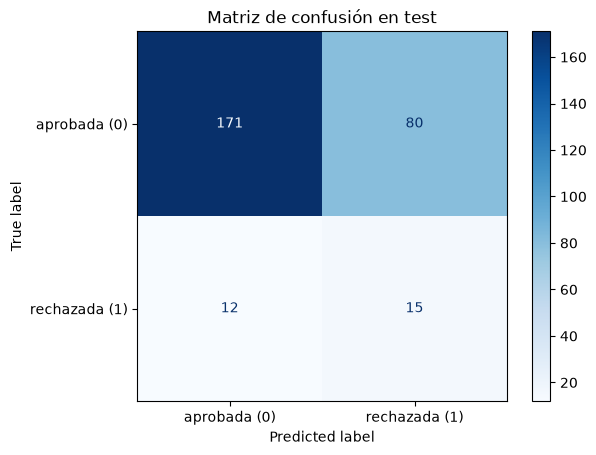

TN=171  FP=80  FN=12  TP=15


In [19]:
# Filas = valor real, columnas = predicción; la positiva (rechazada) es la clase 1
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["aprobada (0)", "rechazada (1)"]).plot(cmap="Blues")
plt.title("Matriz de confusión en test"); plt.grid(False); plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")

| Celda | Significado de negocio |
|---|---|
| **TN** | Cliente bueno al que se **aprueba** correctamente. |
| **FP** | Cliente bueno al que el modelo **rechaza**: se pierde un cliente rentable (coste de oportunidad). |
| **FN** | Cliente que debía rechazarse y se **aprueba**: riesgo de impago. |
| **TP** | Cliente de riesgo al que se **rechaza** correctamente: pérdida evitada. |

**¿Qué error es más costoso?** Normalmente **aprobar a quien debía ser rechazado (FN)**: se presta dinero que puede no recuperarse (principal, gestión de cobro, provisiones). Rechazar a un buen cliente (FP) solo supone dejar de ganar su margen. Por eso aquí importa más el **recall** de la clase rechazada; asumir más falsos positivos es razonable si esos casos se derivan a revisión manual.

### Coeficientes del modelo
Para ver qué variables pesan más en el rechazo, miro los coeficientes de la regresión logística del Pipeline definitivo. Como todas las numéricas están escaladas, los coeficientes son comparables entre sí: **positivo = aumenta la probabilidad de rechazo, negativo = la reduce** (el resto de variables constante).

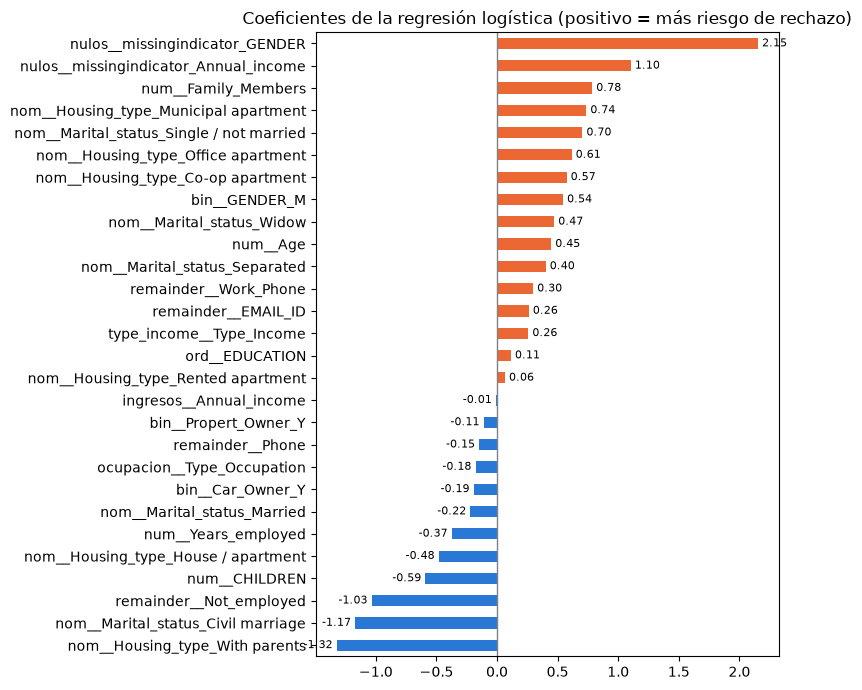

In [20]:
nombres = pipe[:-1].get_feature_names_out()          # nombres de las columnas tras el preprocesado
coef = pipe[-1].coef_[0]
coef = pd.Series(coef, index=nombres).sort_values()

ax = coef.plot.barh(figsize=(8, 7), color=np.where(coef > 0, "#eb6834", "#2a78d6"),
                    title="Coeficientes de la regresión logística (positivo = más riesgo de rechazo)")
ax.bar_label(ax.containers[0], fmt="%.2f", padding=3, fontsize=8)
plt.axvline(0, color="grey", lw=1); plt.tight_layout(); plt.show()

**Lectura (con cautela):**
- Los coeficientes más grandes son los **indicadores de nulo** (`GENDER` ≈ +2,2 y `Annual_income` ≈ +1,1): tener esos datos ausentes sube mucho el riesgo de rechazo. Es coherente con el apartado 2, pero el de `GENDER` se apoya en solo 7 filas, así que no debe tomarse como una regla.
- Reducen el riesgo de rechazo: vivir con los padres, `Civil marriage`, no estar empleado (`Not_employed`) y más años de antigüedad.
- Lo aumentan: estar soltero/a, más miembros en la familia, más edad y algunos tipos de vivienda minoritarios (`Municipal`, `Office`, `Co-op`).
- `CHILDREN` (negativo) y `Family_Members` (positivo) tienen signos opuestos porque están muy correlacionadas (0,89): hay que leerlas juntas, no por separado.
- Los coeficientes describen cómo se comportó la entidad en el pasado (asociación), no causas, y con pocos casos rechazados son inestables.

## 10. Conclusiones

**Datos y preprocesado.** 1.548 clientes unidos por `Ind_ID` (*inner join* uno a uno); se eliminaron 162 duplicados con la misma etiqueta y quedaron 1.386, con ~10 % de solicitudes rechazadas. Se descartaron `Ind_ID` y `Mobile_phone` (constante). `Work_Phone`, `Phone` y `EMAIL_ID` no muestran asociación con el target (chi-cuadrado) pero se mantuvieron. Hallazgos del análisis: los nulos de `GENDER` y `Annual_income` se asocian a más rechazo (por eso llevan indicador de nulo), `Type_Occupation` tiene un 32 % de nulos y casi todos los pensionistas (98 %) carecen de ocupación, y `Employed_days = 365243` es un código de "no trabaja".

**Resultados (test: 278 clientes, 27 rechazadas).**

| Modelo | Accuracy | Precision | Recall | F1 |
|---|---|---|---|---|
| Dummy (siempre aprobada) | 0,903 | 0 | 0 | 0 |
| Regresión logística sin `class_weight` | 0,903 | 0 | 0 | 0 |
| Regresión logística `class_weight="balanced"` | 0,669 | 0,158 | 0,556 | 0,246 |

- Sin tener en cuenta el desbalance, el modelo equivale al Dummy: su 90 % de accuracy es engañoso.
- Con `class_weight="balanced"` detecta **15 de las 27** solicitudes que debían rechazarse (recall 0,56), a costa de **80 falsos positivos** (precision 0,16). Es el compromiso esperable y el que más conviene cuando el FN es el error caro.
- En validación cruzada sobre train el modelo da recall 0,49 ± 0,07 y F1 0,21 ± 0,03, algo por debajo del test (0,56 y 0,25). El test cae dentro de la variación entre folds y solo tiene 27 positivos, así que la diferencia es compatible con ruido y las cifras de CV son más fiables.
- `class_weight` no mejora la capacidad de discriminación: el ROC-AUC es igual con y sin pesos (≈ 0,60 en CV, 0,67 en test; PR-AUC ≈ 0,23 en CV y 0,24 en test frente a una prevalencia de 0,10). Solo mueve el punto de trabajo hacia más recall y menos precision.
- Proceso sin fuga de datos: duplicados eliminados antes de dividir, división estratificada, imputación, indicadores de nulo, Target Encoding y escalado dentro del Pipeline, ajustados solo con *train*, y elección de `class_weight="balanced"` por validación cruzada sobre train.
- **Variables más influyentes** (coeficientes): los indicadores de nulo (`GENDER`, `Annual_income`), vivir con los padres, el estado civil y no estar empleado. `CHILDREN` y `Family_Members` deben leerse juntas por su alta correlación. Son asociaciones con decisiones pasadas, no causas.
- **Uso recomendado:** como filtro de primera revisión que prioriza qué solicitudes mira una persona, no como decisión automática de rechazo.

**Limitaciones**
- Rendimiento modesto: ROC-AUC ≈ 0,6-0,7. Las variables explican poco la decisión histórica y un modelo lineal no capta interacciones.
- Pocos datos y solo 27 positivos en test: las métricas son muy inestables y deben leerse como orientativas.
- Precision muy baja: usado solo, rechazaría a muchos buenos clientes (80 de 251).
- Las etiquetas son decisiones pasadas de la entidad (pueden tener sesgos), no impagos reales; y hay 9 perfiles idénticos con decisiones contradictorias (ruido irreducible).
- El indicador de nulo de `GENDER` se apoya en solo 7 filas.
- Se usó el umbral 0,5 sin optimizar el coste real de cada error, y `GENDER` como variable puede plantear problemas de equidad.
- Se mantuvieron variables con coeficientes cercanos a cero (`Work_Phone`, `Phone`, `EMAIL_ID`, `Propert_Owner`, `Car_Owner`…) sin validar si sobran.

**Posibles mejoras**
- Probar Random Forest o XGBoost y comparar con validación cruzada.
- Selección de variables dentro del Pipeline (regularización L1 o `SelectFromModel`) evaluada con CV, para descartar las de coeficiente casi nulo.
- Ajustar el umbral de decisión según el coste de FN y FP (la curva precisión-recall muestra el compromiso), y derivar los casos dudosos a revisión manual.
- Crear nuevas variables (ingresos por miembro de la familia, tramos de edad), ajustar hiperparámetros con `GridSearchCV` y probar remuestreo (SMOTE) dentro del Pipeline.
- Conseguir más datos, sobre todo de la clase rechazada.

## Declaración de uso de IA
He utilizado **Claude Code** como herramienta de apoyo durante el trabajo. En concreto:
- Revisión del notebook y detección de puntos a mejorar.
- Modificaciones del notebook a partir de esa revisión: evitando repetición de código, revisión de la estructura y corrección de la misma, así como propuestas de mejora para una correcta organización.